In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the original dataset
data = pd.read_excel("Folds5x2_pp.xlsx", sheet_name=0)

# Remove duplicate rows
clean_data = data.drop_duplicates().copy()

# Check the cleaned dataset
print("Dataset shape:", clean_data.shape)

print("\nFirst five rows:")
print(clean_data.head())

Dataset shape: (9527, 5)

First five rows:
      AT      V       AP     RH      PE
0  14.96  41.76  1024.07  73.17  463.26
1  25.18  62.96  1020.04  59.08  444.37
2   5.11  39.40  1012.16  92.14  488.56
3  20.86  57.32  1010.24  76.64  446.48
4  10.82  37.50  1009.23  96.62  473.90


In [2]:
from sklearn.model_selection import train_test_split

# Define input features and output target
X = clean_data[["AT", "V", "AP", "RH"]]
y = clean_data["PE"]

# Split data into 70% training and 30% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

# Split temporary data into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

# Check dataset sizes
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

Training samples: 6668
Validation samples: 1429
Test samples: 1430


In [4]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate mean power output from training data only
baseline_mean = y_train.mean()

# Predict the same value for all validation samples
baseline_val_pred = np.full(len(y_val), baseline_mean)

# Evaluate baseline performance
baseline_mae = mean_absolute_error(y_val, baseline_val_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_val, baseline_val_pred))
baseline_r2 = r2_score(y_val, baseline_val_pred)

print("Mean Baseline Results:")
print(f"Predicted Power Output: {baseline_mean:.2f} MW")
print(f"Validation MAE: {baseline_mae:.3f} MW")
print(f"Validation RMSE: {baseline_rmse:.3f} MW")
print(f"Validation R2: {baseline_r2:.3f}")

Mean Baseline Results:
Predicted Power Output: 454.26 MW
Validation MAE: 15.193 MW
Validation RMSE: 17.311 MW
Validation R2: -0.001


In [6]:
from sklearn.linear_model import LinearRegression

# Create a linear regression model
linear_model = LinearRegression()

# Train the model using training data
linear_model.fit(X_train, y_train)

# Predict power output for validation data
linear_val_pred = linear_model.predict(X_val)

# Evaluate model performance
linear_mae = mean_absolute_error(y_val, linear_val_pred)
linear_rmse = np.sqrt(mean_squared_error(y_val, linear_val_pred))
linear_r2 = r2_score(y_val, linear_val_pred)

print("Linear Regression Results:")
print(f"Validation MAE: {linear_mae:.3f} MW")
print(f"Validation RMSE: {linear_rmse:.3f} MW")
print(f"Validation R2: {linear_r2:.3f}")

Linear Regression Results:
Validation MAE: 3.587 MW
Validation RMSE: 4.630 MW
Validation R2: 0.928


In [9]:
results = pd.DataFrame({
    "Model": ["Mean Baseline", "Linear Regression"],
    "MAE (MW)": [baseline_mae, linear_mae],
    "RMSE (MW)": [baseline_rmse, linear_rmse],
    "R2": [baseline_r2, linear_r2]
})

print("Model Comparison:")
display(results.round(3))

# Calculate improvement in MAE
mae_improvement = (baseline_mae - linear_mae) / baseline_mae * 100

print(f"\nMAE reduction: {mae_improvement:.2f}%")

Model Comparison:


,Model,MAE (MW),RMSE (MW),R2
0,Mean Baseline,15.193,17.311,-0.001
1,Linear Regression,3.587,4.630,0.928



MAE reduction: 76.39%


In [10]:
# Display the intercept
print("Linear Regression Intercept:")
print(f"{linear_model.intercept_:.4f} MW")

# Display coefficients for each input feature
coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": linear_model.coef_
})

print("\nLinear Regression Coefficients:")
display(coefficients.round(4))

Linear Regression Intercept:
447.6901 MW

Linear Regression Coefficients:


,Feature,Coefficient
0,AT,-1.9728
1,V,-0.2364
2,AP,0.0686
3,RH,-0.1542


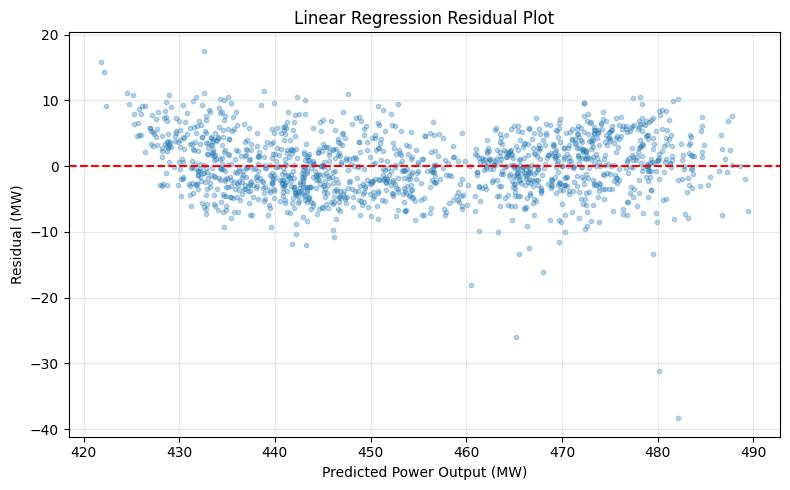

In [12]:
# Calculate residuals
residuals = y_val - linear_val_pred

# Plot residuals against predicted power output
plt.figure(figsize=(8, 5))

plt.scatter(linear_val_pred, residuals, alpha=0.3, s=10)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Power Output (MW)")
plt.ylabel("Residual (MW)")
plt.title("Linear Regression Residual Plot")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()